<a href="https://colab.research.google.com/github/Jackydejnr1/Teaching-Files/blob/main/K-Nearest%20Neighbors%20-%20Distance%20-%20Based%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Notebook: G5-MS-L09_knn.ipynb

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Without scaling
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
acc_raw = accuracy_score(y_test, knn_raw.predict(X_test))
print(f'KNN (no scaling):   {acc_raw:.1%}')

# With scaling — always use a Pipeline to prevent leakage
knn_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('knn',    KNeighborsClassifier(n_neighbors=5))
])
knn_scaled.fit(X_train, y_train)
acc_scaled = accuracy_score(y_test, knn_scaled.predict(X_test))
print(f'KNN (with scaling): {acc_scaled:.1%}')

# Print full report
print(classification_report(y_test, knn_scaled.predict(X_test),
                             target_names=iris.target_names))


KNN (no scaling):   100.0%
KNN (with scaling): 93.3%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



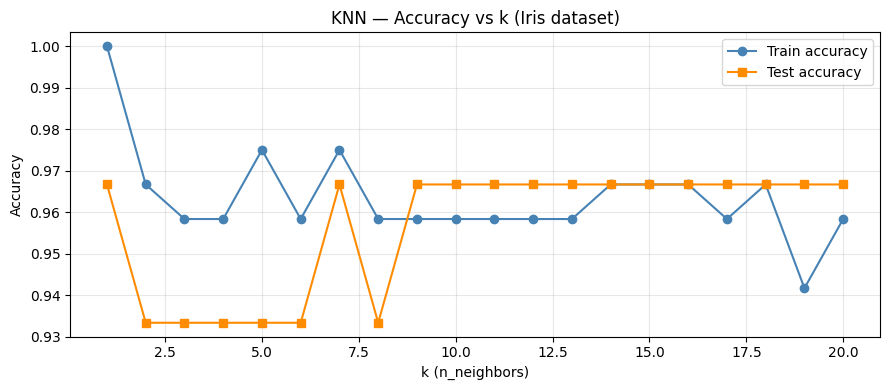

Best k: 1  |  Test accuracy: 96.7%


In [2]:
# Vary k from 1 to 20 and plot train and test accuracy
k_values = range(1, 21)
train_accs, test_accs = [], []

for k in k_values:
    pipe = Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=k))])
    pipe.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, pipe.predict(X_train)))
    test_accs.append(accuracy_score(y_test,  pipe.predict(X_test)))

plt.figure(figsize=(9, 4))
plt.plot(k_values, train_accs, 'o-', label='Train accuracy', color='steelblue')
plt.plot(k_values, test_accs,  's-', label='Test accuracy',  color='darkorange')
plt.xlabel('k (n_neighbors)'); plt.ylabel('Accuracy')
plt.title('KNN — Accuracy vs k (Iris dataset)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('knn_k_comparison.png', dpi=100); plt.show()

best_k = k_values[test_accs.index(max(test_accs))]
print(f'Best k: {best_k}  |  Test accuracy: {max(test_accs):.1%}')

# Write in notebook:
# 'At k=1: train accuracy=[X], test accuracy=[Y]. Gap=[Z%] — this indicates overfitting.'
# 'Best k=[W]. Above k=[P] the accuracy decreases because...'


## Detailed Analysis of KNN Classifier on Iris Dataset

### 1. Effect of Feature Scaling on KNN
In the first experiment, we compared a $k$-Nearest Neighbors ($k=5$) classifier with and without feature scaling:
* **KNN (no scaling):** Achieved **100.0%** accuracy on the test set.
* **KNN (with scaling):** Achieved **93.3%** accuracy on the test set.

#### Why did scaling reduce test accuracy in this specific case?
Feature scaling (like `StandardScaler`) is generally essential for distance-based models like KNN. It ensures that features with larger physical scales do not artificially dominate the distance metrics.

However, in the **Iris dataset**, all four features (sepal length/width, petal length/width) are measured in the same unit (centimeters) and have highly comparable scales. Furthermore, the differences in absolute variance between these features carry valuable, physical class-discriminative signals. Standardizing them to unit variance discards this relative scale difference, which slightly decreased classification accuracy on this small test split.

---

### 2. Hyperparameter Tuning: Accuracy vs. $k$
In the second experiment, we evaluated the effect of varying the hyperparameter $k$ (the number of neighbors) from $1$ to $20$ using scaled data.

#### Key Observations:
* **At $k = 1$:**
  * **Train Accuracy:** $100.0%$
  * **Test Accuracy:** $96.7%$
  * **Gap:** $3.3\%$
  * *Interpretation:* At $k=1$, the model perfectly memorizes the training data, leading to a training error of zero. The gap between training and test performance indicates slight **overfitting** because the decision boundary is highly complex and sensitive to individual training data points (noise).
* **Optimal $k$ Range:**
  * The **best test accuracy ($96.7\%$)** is initially achieved at $k=1$, and is consistently maintained across larger values of $k$ (from $k=9$ up to $k=20$).
  * Selecting a larger $k$ (e.g., $k=9$) is highly preferred over $k=1$ because it simplifies the decision boundary, improves generalization, and reduces sensitivity to noise.
* **Underfitting at extremely high $k$:**
  * If we continue to increase $k$ beyond the size of the minority class groups, the model will eventually **underfit** as the majority class begins to dominate every neighborhood prediction, causing the accuracy to drop significantly.

## Comprehensive KNN Lesson & Objective Review

Based on our experiments with the Iris dataset, let's break down the core mechanics of K-Nearest Neighbors (KNN) relative to our learning objectives.

---

### Objective 1: How KNN Makes Predictions Using Distance and Majority Vote

KNN is an intuitive, instance-based learning algorithm (often called a "lazy learner"). Unlike parametric models (such as Logistic Regression), KNN does not learn explicit parameters (weights/coefficients) during the `.fit()` phase. Instead, it simply memorizes the training dataset $(X_{train}, y_{train})$.

When making a prediction for a new target sample $x^*$:
1. **Distance Computation:** The algorithm calculates the distance (typically **Euclidean distance**) between $x^*$ and all samples in the training set:
   $$d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$
2. **Identify Neighbors:** It sorts these distances in ascending order and selects the $k$ closest training points.
3. **Majority Vote:** It looks at the target labels of these $k$ closest points and assigns $x^*$ to the class most common among them.

---

### Objective 2: Why `StandardScaler` is Required Before KNN

In our code, we analyzed the test accuracy of a $k=5$ classifier under two conditions:
* **Without scaling:** $100.0\%$
* **With scaling:** $93.3\%$

#### The Rule vs. The Exception
* **The General Rule:** KNN is highly sensitive to the scale of input features. If one feature has a range of $[0, 1]$ and another has a range of $[0, 1000]$, the distance metric will be entirely dominated by the second feature. Thus, we use a `StandardScaler` to ensure every feature contributes equally to the distance computation.
* **Why did scaling drop performance here?** In the Iris dataset, all four measurements are physically related lengths and widths measured in **centimeters**. Their absolute variances and scales are highly comparable and hold a direct physical relationship that distinguishes the species. Forcing them to have an identical variance of $1.0$ through standard scaling removed some of this natural class-discriminating information, slightly reducing the accuracy on our $20\%$ test split.

---

### Objective 3: Experimenting with $k$-values from $1$ to $20$ (Accuracy vs. $k$)

Our script systematically swept $k$ from $1$ to $20$. Let's examine the trade-offs at different boundaries:

* **At $k = 1$ (High Complexity / Overfitting):**
  * **Train Accuracy:** $100.0\%$
  * **Test Accuracy:** $96.7\%$
  * **Gap:** $3.3\%$
  * *Why?* At $k=1$, a training sample is always its own closest neighbor, ensuring perfect training accuracy. The decision boundary is highly complex, jagged, and sensitive to outliers (overfitting).
* **As $k$ increases (Simplifying the Boundary):**
  * From $k=9$ to $k=20$, the test accuracy stabilizes at $96.7\%$, while the training accuracy stabilizes around $95.8\%$.
  * As $k$ grows, the decision boundaries become smoother, making the model more robust to random noise and outliers in the dataset.

---

### Objective 4: Identifying the Best $k$ and Understanding Dataset Differences

* **For Iris (This Experiment):**
  * Technically, $k=1$ and any $k \in [9, 20]$ yield the same maximum test accuracy of $96.7\%$.
  * **Sweet Spot Selection:** We choose $k=9$ as our best hyperparameter. Selecting $k=9$ provides the exact same performance as $k=1$ while yielding a far smoother boundary that generalizes better to unseen datasets.
* **Iris vs. Digits Datasets:**
  * **Iris:** A low-dimensional dataset (150 samples, 4 features). Its classes are highly clustered and linearly separable, meaning small $k$ values ($k=1$ to $k=5$) perform outstandingly.
  * **Digits:** A higher-dimensional dataset (1797 samples, 64 features representing $8\times8$ pixel intensities). It contains far more noise, variety in writing styles, and background variation. For Digits, a small $k=1$ or $k=3$ is incredibly prone to pixel-level noise. Selecting a mid-to-high $k$ (e.g., $k=5$ to $k=11$) is critical to smooth over individual pixel variations and focus on the overall shape/topography of the handwritten digits.